In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# 01 - Data coverage
What the panel contains, and where the gaps are, before any comparison.

In [2]:
LAST = 2024  # last year with broad coverage (2025 is provisional for many series)
cov = (panel[panel.iso3.isin(EU27_ISO3 + BENCHMARKS) & panel.year.between(2005, LAST)]
       .groupby("indicator").agg(countries=("iso3", "nunique"), first_year=("year", "min"), last_year=("year", "max"),
                                    obs=("value", "size"), source=("source", "first")))
it = panel[(panel.iso3 == ITALY) & panel.year.between(2005, LAST)].groupby("indicator").year.agg(italy_years="nunique")
cov = cov.join(it)
display(cov.sort_values("italy_years").head(15))
print(len(cov), "indicators;", int((cov.italy_years < 20).sum()), "with fewer than 20 Italian years in 2005-2024")

,countries,first_year,last_year,obs,source,italy_years
indicator,,,,,,
piaac_literacy_16_24,21,2023,2023,21,"manual:OECD Education GPS, Survey of Adult Ski...",1.0
piaac_high_literacy_pct,21,2023,2023,21,"manual:OECD Education GPS, Survey of Adult Ski...",1.0
piaac_literacy_25_34,21,2023,2023,21,"manual:OECD Education GPS, Survey of Adult Ski...",1.0
piaac_adaptive_problem_solving,21,2023,2023,21,"manual:OECD Education GPS, Survey of Adult Ski...",1.0
piaac_literacy_55_65,21,2023,2023,21,"manual:OECD Education GPS, Survey of Adult Ski...",1.0
piaac_literacy_below_upper_secondary,21,2023,2023,21,"manual:OECD Education GPS, Survey of Adult Ski...",1.0
piaac_literacy_men,21,2023,2023,21,"manual:OECD Education GPS, Survey of Adult Ski...",1.0
piaac_literacy_parent_tertiary,21,2023,2023,21,"manual:OECD Education GPS, Survey of Adult Ski...",1.0
piaac_literacy_parents_no_upper_secondary,21,2023,2023,21,"manual:OECD Education GPS, Survey of Adult Ski...",1.0


176 indicators; 90 with fewer than 20 Italian years in 2005-2024


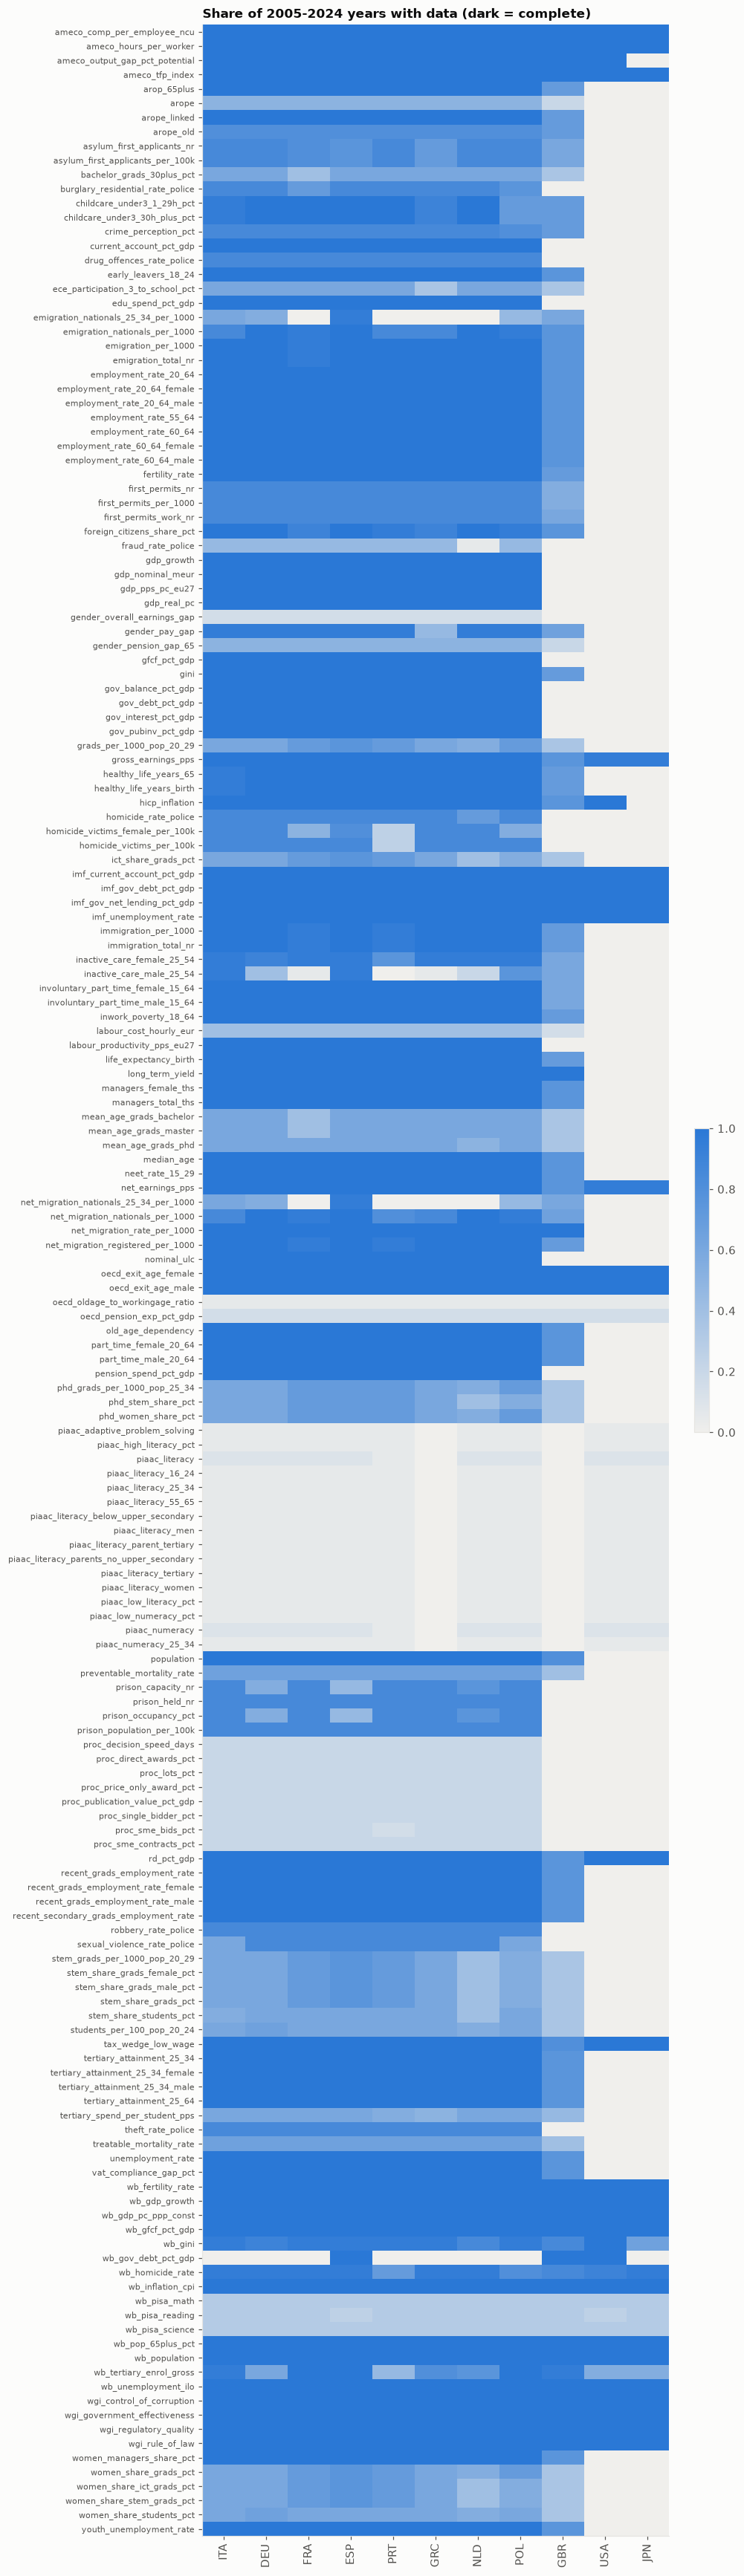

In [3]:
# share of the 20 years 2005-2024 available, per indicator and country group member (Italy + peers + benchmarks)
cols = [ITALY, *PEERS, *BENCHMARKS]
d = panel[panel.year.between(2005, LAST) & panel.iso3.isin(cols)]
share = (d.groupby(["indicator", "iso3"]).year.nunique().unstack() / 20).reindex(columns=cols).fillna(0)
fig, ax = plt.subplots(figsize=(8, 0.22 * len(share) + 1.2))
im = ax.imshow(share.values, cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("s", ["#f0efec", "#2a78d6"]), vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(cols)), cols, rotation=90); ax.set_yticks(range(len(share)), share.index, fontsize=7); ax.grid(False)
ax.set_title("Share of 2005-2024 years with data (dark = complete)")
fig.colorbar(im, ax=ax, fraction=0.03); save(fig, "01_coverage")

**Reading the chart:** US/JP/GBR rows are empty for Eurostat-only series, so benchmark comparisons use the `imf_*`, `wb_*`, `ameco_*` indicators. Gaps for Italy itself are limited to `gini`, `arope` (2015+), PISA (triennial) and manually-entered series - see `docs/data_dictionary.md`.